# Práctica 5 — Correlación de Pearson

Trabajaremos con `household_power_consumption_zscore.csv`, generado por `normalizacion.ipynb`.

**Criterio temporal:** la fecha de corte es el **1 de enero de 2010** (exclusiva para entrenamiento). Las correlaciones que utilizaremos para decidir variables redundantes se calculan **únicamente con el periodo de entrenamiento**, sin incluir 2010.




### 1. Encontrar los archivos del proyecto


In [12]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

ARCHIVO_ZSCORE = "household_power_consumption_zscore.csv"

ruta_csv = None
for base in (Path.cwd(), *Path.cwd().parents):
    for proyecto_candidato in (base / "proyecto", base):
        candidato = proyecto_candidato / "data" / "data-processed" / ARCHIVO_ZSCORE
        if candidato.is_file():
            ruta_csv = candidato.resolve()
            proyecto_dir = proyecto_candidato.resolve()
            break
    if ruta_csv is not None:
        break

if ruta_csv is None:
    raise FileNotFoundError(
        "No se encontró household_power_consumption_zscore.csv. "
        "Ejecuta primero normalizacion.ipynb para generar este archivo."
    )

sys.path.insert(0, str(proyecto_dir / "src"))
from cleaning.preprocessing import NUMERIC_COLUMNS

numericas = list(NUMERIC_COLUMNS)
print("Archivo encontrado:", ruta_csv)
print("Variables numéricas:", numericas)


Archivo encontrado: /home/mirezz/Documentos/Practica5_Norma_PCA/proyecto/data/data-processed/household_power_consumption_zscore.csv
Variables numéricas: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


### 2. Cargar datos estandarizados y separar por fecha

El CSV usa **punto y coma (`;`) como separador**, de acuerdo con la exportación de nuestro notebook anterior. `Datetime` es una fecha, por lo que **no** se incluye en la matriz de Pearson.

La fecha de corte que usamos antes fue `2010-01-01`, así que mantendremos la misma división:

- **Entrenamiento:** registros anteriores al 1 de enero de 2010.
- **Prueba:** registros desde el 1 de enero de 2010. **No se usarán para seleccionar variables.**


In [13]:
df_zscore = pd.read_csv(
    ruta_csv,
    sep=";",
    usecols=["Datetime", *numericas],
    parse_dates=["Datetime"],
)

fecha_corte = pd.Timestamp("2010-01-01")
mascara_entrenamiento = df_zscore["Datetime"] < fecha_corte

entrenamiento = df_zscore.loc[mascara_entrenamiento, numericas]

if entrenamiento.empty or (~mascara_entrenamiento).sum() == 0:
    raise ValueError("La separación temporal no produjo datos de entrenamiento y prueba.")
if entrenamiento.isna().any().any():
    raise ValueError("Hay valores faltantes en las variables de entrenamiento.")

print(f"Total de registros:       {len(df_zscore):,}")
print(f"Registros de entrenamiento: {len(entrenamiento):,}")
print(f"Registros de prueba:       {(~mascara_entrenamiento).sum():,}")
print(f"Última fecha de entrenamiento: {df_zscore.loc[mascara_entrenamiento, 'Datetime'].max()}")
print("Columnas analizadas:", ", ".join(entrenamiento.columns))
display(entrenamiento.head())


Total de registros:       2,049,280
Registros de entrenamiento: 1,591,886
Registros de prueba:       457,394
Última fecha de entrenamiento: 2009-12-31 23:59:00
Columnas analizadas: Global_active_power, Global_reactive_power, Voltage, Global_intensity, Sub_metering_1, Sub_metering_2, Sub_metering_3


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2.857736,2.641943,-1.749768,2.994735,-0.184404,-0.059039,1.289969
1,3.907056,2.802641,-2.114446,3.998119,-0.184404,-0.059039,1.170164
2,3.919897,3.356158,-2.216918,3.998119,-0.184404,0.107234,1.289969
3,3.932739,3.391869,-2.081294,3.998119,-0.184404,-0.059039,1.289969
4,2.353255,3.623988,-1.496603,2.427606,-0.184404,-0.059039,1.289969


### 3. ¿Qué calcula Pearson?

El coeficiente de correlación lineal de Pearson, entre dos variables $X$ y $Y$, se puede expresar como:

$$
r_{XY}=\frac{\operatorname{cov}(X,Y)}{\sigma_X\sigma_Y}
$$

Sus valores están entre **-1 y 1**:

- **Cercano a +1:** relación lineal positiva fuerte; cuando una sube, la otra tiende a subir.
- **Cercano a -1:** relación lineal negativa fuerte; cuando una sube, la otra tiende a bajar.
- **Cercano a 0:** relación lineal débil o nula; podría haber otro tipo de relación no lineal.



### 4. Calcular la matriz de correlación


In [14]:
matriz_pearson = entrenamiento.corr(method="pearson")

display(matriz_pearson.round(4))
print("Dimensiones de la matriz:", matriz_pearson.shape)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.0000,0.2483,-0.3975,0.9990,0.4845,0.4411,0.6288
Global_reactive_power,0.2483,1.0000,-0.1151,0.2667,0.1350,0.1420,0.0807
Voltage,-0.3975,-0.1151,1.0000,-0.4087,-0.1957,-0.1714,-0.2735
Global_intensity,0.9990,0.2667,-0.4087,1.0000,0.4884,0.4470,0.6173
Sub_metering_1,0.4845,0.1350,-0.1957,0.4884,1.0000,0.0585,0.1070
Sub_metering_2,0.4411,0.1420,-0.1714,0.4470,0.0585,1.0000,0.0869
Sub_metering_3,0.6288,0.0807,-0.2735,0.6173,0.1070,0.0869,1.0000


Dimensiones de la matriz: (7, 7)


### 5. Comprobar que la matriz es válida

Una matriz de correlación de Pearson debe cumplir que:

1. Su tamaño es 7 × 7 para nuestras siete variables.
2. Su **diagonal vale 1**, pues cada variable está perfectamente correlacionada consigo misma.
3. Es **simétrica**: la correlación entre A y B es igual a la de B y A.
4. Ningún coeficiente es menor que -1 ni mayor que 1 (salvo diferencias diminutas de precisión numérica).

Estos chequeos no demuestran qué variables son redundantes, pero confirman que el cálculo tiene la estructura esperada.


In [15]:
valores = matriz_pearson.to_numpy()

assert matriz_pearson.shape == (len(numericas), len(numericas))
assert np.isfinite(valores).all(), "Hay correlaciones indefinidas (revisar columnas constantes)."
assert np.allclose(valores, valores.T, atol=1e-10)
assert np.allclose(np.diag(valores), 1.0, atol=1e-10)
assert (np.abs(valores) <= 1 + 1e-10).all()

print("Validaciones de la matriz de Pearson superadas.")


Validaciones de la matriz de Pearson superadas.


### 6. Guardar la matriz 

Al guardar los coeficientes, podemos consultarlos posteriormente sin recalcular la matriz. **No se sobrescribe** el CSV limpio ni el CSV estandarizado.

In [16]:
ruta_matriz = proyecto_dir / "data" / "data-processed" / "matriz_pearson_entrenamiento.csv"
matriz_pearson.to_csv(ruta_matriz, sep=";", index=True)
print("Matriz guardada en:", ruta_matriz)


Matriz guardada en: /home/mirezz/Documentos/Practica5_Norma_PCA/proyecto/data/data-processed/matriz_pearson_entrenamiento.csv


### 7. Interpretación 


Los resultados muestran una **correlación positiva casi perfecta (r = 0.999)** entre `Global_active_power` y `Global_intensity`, lo que indica una posible redundancia entre ambas variables.

También encontramos correlaciones positivas moderadas entre `Global_active_power` y `Sub_metering_3` (r = 0.629), así como una correlación negativa moderada entre `Voltage` y `Global_intensity` (r = -0.409).

Por otro lado, `Global_reactive_power` presenta correlaciones débiles con las demás variables, lo que sugiere que aporta información menos relacionada linealmente con ellas.

En conclusión, **la principal candidata a reducción por redundancia es la pareja `Global_active_power` y `Global_intensity`**. Sin embargo, todavía debemos definir un umbral de correlación para justificar qué variables conservar o descartar.


## Mapa de calor


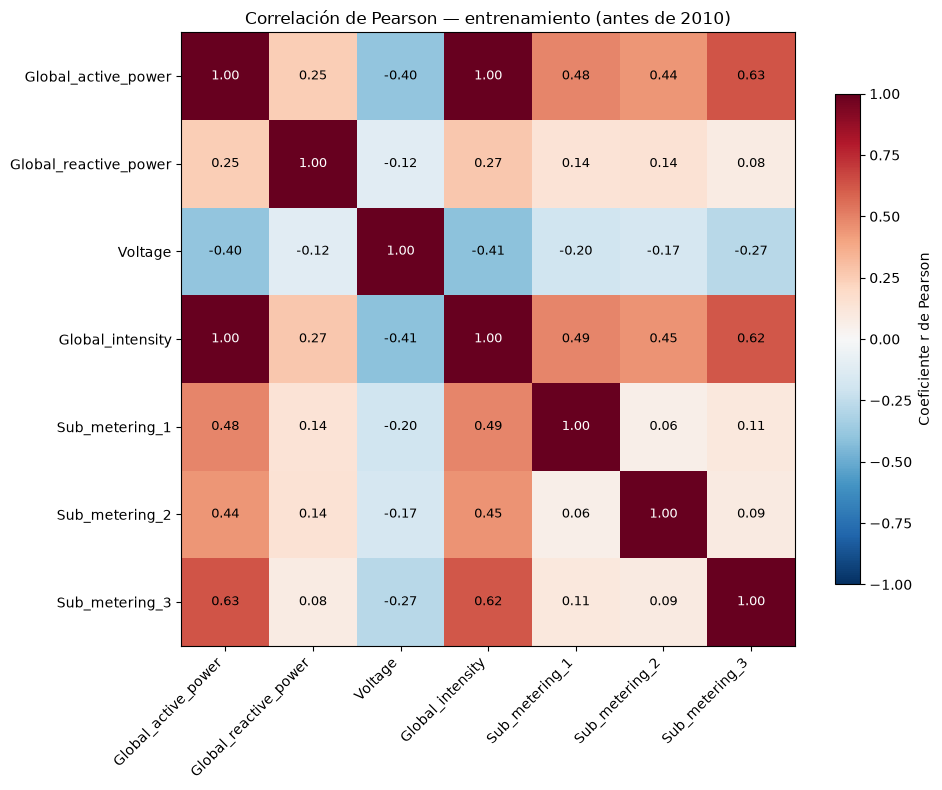

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(matriz_pearson, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(numericas)), labels=numericas, rotation=45, ha="right")
ax.set_yticks(range(len(numericas)), labels=numericas)
ax.set_title("Correlación de Pearson — entrenamiento (antes de 2010)")

for i in range(len(numericas)):
    for j in range(len(numericas)):
        valor = matriz_pearson.iat[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) >= 0.65 else "black", fontsize=9)

fig.colorbar(imagen, ax=ax, label="Coeficiente r de Pearson", shrink=0.8)
fig.tight_layout()
plt.show()

## 8. Identificar pares con correlación alta



In [18]:
from itertools import combinations

filas_pares = []
for variable_1, variable_2 in combinations(numericas, 2):
    r = float(matriz_pearson.loc[variable_1, variable_2])
    filas_pares.append({
        "variable_1": variable_1,
        "variable_2": variable_2,
        "r": r,
        "correlacion_absoluta": abs(r),
        "direccion": "positiva" if r > 0 else "negativa" if r < 0 else "sin relación lineal",
    })

pares_ordenados = (
    pd.DataFrame(filas_pares)
      .sort_values("correlacion_absoluta", ascending=False)
      .reset_index(drop=True)
)
print(f"Pares únicos sin diagonal: {len(pares_ordenados)} (para 7 variables deben ser 21)")
display(pares_ordenados.head(12).round(4))

Pares únicos sin diagonal: 21 (para 7 variables deben ser 21)


,variable_1,variable_2,r,correlacion_absoluta,direccion
0,Global_active_power,Global_intensity,0.9990,0.9990,positiva
1,Global_active_power,Sub_metering_3,0.6288,0.6288,positiva
2,Global_intensity,Sub_metering_3,0.6173,0.6173,positiva
3,Global_intensity,Sub_metering_1,0.4884,0.4884,positiva
4,Global_active_power,Sub_metering_1,0.4845,0.4845,positiva
5,Global_intensity,Sub_metering_2,0.4470,0.4470,positiva
6,Global_active_power,Sub_metering_2,0.4411,0.4411,positiva
7,Voltage,Global_intensity,-0.4087,0.4087,negativa
8,Global_active_power,Voltage,-0.3975,0.3975,negativa
9,Voltage,Sub_metering_3,-0.2735,0.2735,negativa


## 9. Definir y justificar un umbral

**Propuesta inicial:** considerar como posibles variables redundantes aquellas parejas con $|r| \geq 0.90$.

El valor **0.90 no es una regla universal**: lo elegimos como criterio conservador para evitar descartar variables solo porque tengan una relación moderada. Evaluamos correlaciones **positivas o negativas** por igual. El umbral puede revisarse si el contexto de las variables o el objetivo del modelo lo requieren.

**Importante:** un valor alto señala *candidatos a redundancia*, pero no decide automáticamente cuál variable debe eliminarse.

In [19]:
UMBRAL_CORRELACION = 0.90  # Podemos ajustarlo segun EL CRITERIO DE LO QUE SE BUSCA

pares_altamente_correlacionados = pares_ordenados.loc[
    pares_ordenados["correlacion_absoluta"] >= UMBRAL_CORRELACION
].copy()

print(f"Umbral aplicado: |r| >= {UMBRAL_CORRELACION:.2f}")
print(f"Pares que superan el umbral: {len(pares_altamente_correlacionados)}")
display(pares_altamente_correlacionados.round(4))

Umbral aplicado: |r| >= 0.90
Pares que superan el umbral: 1


,variable_1,variable_2,r,correlacion_absoluta,direccion
0,Global_active_power,Global_intensity,0.999,0.999,positiva


## 10. Variables a conservar o descartar

En la matriz observada, `Global_active_power` y `Global_intensity` son casi perfectamente correlacionadas. 
Entonces podemos llegar a:

- **Conservar `Global_active_power`** porque representa directamente la potencia activa consumida por el hogar y es una variable central para estudiar su consumo eléctrico.
- **Descartar `Global_intensity` del conjunto reducido** porque su correlación con la anterior es cercana a 1 y aporta información lineal muy parecida.
- **Mantener las otras cinco variables**, cuyo $|r|$ entre pares no alcanza el umbral propuesto.


In [20]:
# Solo aplicamos la decisión si el par supera realmente nuestro umbral.
par_esperado = {"Global_active_power", "Global_intensity"}
existe_par_esperado = any(
    {fila["variable_1"], fila["variable_2"]} == par_esperado
    for _, fila in pares_altamente_correlacionados.iterrows()
)

variables_descartar = ["Global_intensity"] if existe_par_esperado else []
variables_conservar = [v for v in numericas if v not in variables_descartar]

print("Variables a conservar:", variables_conservar)
print("Variables a descartar:", variables_descartar)

if not existe_par_esperado:
    print("ATENCIÓN: la pareja esperada no superó el umbral. Revisa la matriz antes de descartar.")

otros_pares = pares_altamente_correlacionados.loc[
    ~pares_altamente_correlacionados.apply(
        lambda fila: {fila["variable_1"], fila["variable_2"]} == par_esperado,
        axis=1,
    )
]
if not otros_pares.empty:
    print("ATENCIÓN: hay otras parejas sobre el umbral; requieren decisión manual:")
    display(otros_pares.round(4))

resumen_decisiones = pd.DataFrame({
    "variable": numericas,
    "decision": ["Descartar" if v in variables_descartar else "Conservar" for v in numericas],
})
display(resumen_decisiones)

Variables a conservar: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
Variables a descartar: ['Global_intensity']


,variable,decision
0,Global_active_power,Conservar
1,Global_reactive_power,Conservar
2,Voltage,Conservar
3,Global_intensity,Descartar
4,Sub_metering_1,Conservar
5,Sub_metering_2,Conservar
6,Sub_metering_3,Conservar
